# 📊 Curso de Python: Aula 15 - Visualização de Dados com Matplotlib

**Seja muito bem-vindo à nossa aula sobre Matplotlib!**

Uma imagem vale mais que mil números. Na era do Big Data, da Inteligência Artificial e da Computação Científica, a capacidade de **visualizar dados de forma clara, intuitiva e esteticamente agradável** é uma das habilidades mais valiosas para qualquer programador, cientista de dados ou engenheiro.

O cérebro humano processa informações visuais cerca de **60.000 vezes mais rápido** do que tabelas de texto ou números brutos. Gráficos bem construídos nos permitem:
* Identificar tendências, sazonalidades e padrões em séries temporais.
* Detectar anomalias, desvios e *outliers* instantaneamente.
* Compreender correlações entre variáveis complexas.
* Comunicar resultados e *insights* de forma convincente e profissional.

Nesta aula, aprenderemos a utilizar a biblioteca **Matplotlib** (especialmente o módulo `matplotlib.pyplot`), o padrão da indústria para criação de gráficos estáticos, animados e interativos em Python.

---

### 🎯 Objetivos de Aprendizagem da Aula:
1. **Compreender a Arquitetura do Matplotlib**: Entender os conceitos fundamentais de `Figure` (a tela/moldura) e `Axes` (a área de plotagem).
2. **Abordagem Funcional vs Orientada a Objetos (*OO-Style*)**: Dominar o estilo orientado a objetos com `plt.subplots()`, que é a melhor prática recomendada na indústria.
3. **Gráficos de Linhas e Séries Temporais (`ax.plot`)**: Customizar cores, estilos de linha, marcadores, transparência, legendas e grades.
4. **Gráficos de Dispersão e Correlações (`ax.scatter`)**: Mapear terceiras e quartas dimensões com tamanho (`s`), mapa de cores (`c`, `cmap`) e barra de cores (`colorbar`).
5. **Gráficos de Barras (`ax.bar` e `ax.barh`)**: Comparar categorias discretas, adicionar rótulos de valores (`bar_label`) e barras agrupadas/empilhadas.
6. **Histogramas e Distribuições (`ax.hist`)**: Analisar densidade de probabilidade, frequências de eventos, intervalos (`bins`) e marcação de médias com `axvline`.
7. **Múltiplos Subgráficos (*Dashboards* com `plt.subplots`)**: Organizar painéis visuais complexos com grades $N 	imes M$ e ajuste de espaçamento com `tight_layout()`.

---

### 📝 Estrutura das Atividades Práticas:
Para cada tema, você encontrará explicações didáticas com exemplos visuais, seguidas de:
* **Célula de Prática**: Contendo o protótipo com `pass`, chamada de teste e a **Saída Esperada comentada** (elementos visuais obrigatórios).
* **Célula de Resposta Comentada**: Resolução detalhada passo a passo gerando o gráfico com `plt.show()` para validação imediata.

---


In [19]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

## 1. O que é o Matplotlib e sua Anatomia Fundamental

O **Matplotlib** é a biblioteca de visualização de dados mais antiga e consolidada do ecossistema Python, criada em 2003 por John D. Hunter. Ela inspirou diversas outras ferramentas modernas (como Seaborn e pandas plotting) e oferece controle milimétrico sobre cada pixel da imagem gerada.

### 🖼️ A Anatomia de uma Figura no Matplotlib:

Para dominar o Matplotlib sem frustrações, você deve entender a distinção entre os dois elementos centrais:

1. **`Figure` (A Tela / Prancheta)**: É o contêiner geral de mais alto nível. Representa a janela inteira onde tudo é desenhado. Uma figura pode conter um ou vários gráficos (`Axes`), títulos globais, logos e legendas.
2. **`Axes` (O Gráfico / A Área de Plotagem)**: É o gráfico propriamente dito. É a região retangular delimitada por eixos ($X$ e $Y$ em 2D) onde seus dados (linhas, pontos, barras) são desenhados. Contém título, rótulos dos eixos, marcas de graduação (*ticks*) e grades (*grid*).

```
+-------------------------------------------------------------------+
| Figure (A tela toda)                                              |
|                                                                   |
|   +-----------------------------------------------------------+   |
|   | Axes (O gráfico específico)                               |   |
|   |                                                           |   |
|   |   Title: "Vendas ao longo do ano"                         |   |
|   |   ^                                                       |   |
| Y |   |       *--*                                            |   |
| - |   |      /    \       (Dados: plot, scatter, bar...)      |   |
| A |   |     *      *--*                                       |   |
| x |   |    /                                                  |   |
| i |   +------------------------------------->                 |   |
| s |   0           X-Axis (Tempo em Meses)                     |   |
|   |                                                           |   |
|   +-----------------------------------------------------------+   |
+-------------------------------------------------------------------+
```

---

### ⚖️ Abordagem Funcional (Pyplot) vs Orientada a Objetos (OO-Style)

No Matplotlib existem duas formas de criar gráficos:
1. **Estilo Funcional (`plt.plot`, `plt.title`, `plt.xlabel`)**: Rápido para rascunhos rápidos no terminal, mas difícil de customizar em layouts complexos.
2. **Estilo Orientado a Objetos (`fig, ax = plt.subplots(...)`)**: **Recomendado mundialmente**. Permite manipular explicitamente cada objeto `ax` e criar painéis com múltiplos gráficos com total clareza.

Vamos comparar as duas formas no código a seguir:


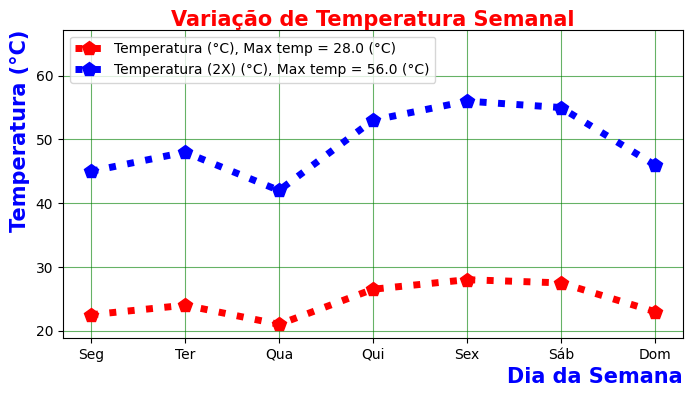

In [67]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Dados de exemplo: Dias da semana e temperatura registrada (°C)
dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
temperaturas_1x = np.array([22.5, 24.0, 21.0, 26.5, 28.0, 27.5, 23.0])
temperaturas_2x = 2*temperaturas_1x


# --- ABORDAGEM ORIENTADA A OBJETOS (OO-Style - RECOMENDADA) ---
fig, ax = plt.subplots(figsize=(8, 4))  # Cria a Figura e o Axes

# Desenhando os dados no objeto ax
ax.plot(dias, temperaturas_1x, color='red', marker='p', markersize=10 ,linewidth=5, 
        linestyle=":", label=f'Temperatura (°C), Max temp = {max(temperaturas_1x) } (°C)')

ax.plot(dias, temperaturas_2x, color='blue', marker='p', markersize=10 ,linewidth=5, 
        linestyle=":", label=f'Temperatura (2X) (°C), Max temp = {max(temperaturas_2x) } (°C)')



# Customizando o Axes
ax.set_title('Variação de Temperatura Semanal', fontsize=15, fontweight='bold', pad=0, loc='center', color='red')
ax.set_xlabel('Dia da Semana', fontsize=15, loc='right', color='blue', fontweight='bold')
ax.set_ylabel('Temperatura (°C)', fontsize=15, loc='top', color='blue', fontweight='bold')
ax.set_ylim( min(temperaturas_1x) * 0.9,  max(temperaturas_2x)*1.2)
ax.grid(True, linestyle='-', alpha=0.6, color='green')
ax.legend(loc='upper left')

# Exibindo o gráfico
plt.show()


## 2. Gráficos de Linha (`ax.plot`) e Customização Completa

O gráfico de linha é a melhor escolha para representar a **evolução contínua de grandezas** ao longo do tempo ou funções matemáticas contínuas.

### 🎨 Principais Parâmetros de Customização de Linhas:
* `color`: Cor da linha (pode ser nome em inglês como `'blue'`, código hexadecimal `'#2ecc71'`, ou tupla RGB).
* `linestyle` (ou `ls`): Estilo do traço:
  * `'-'` : Linha sólida (padrão)
  * `'--'` : Linha tracejada (*dashed*)
  * `'-.'` : Linha traço-ponto (*dash-dot*)
  * `':'` : Linha pontilhada (*dotted*)
* `linewidth` (ou `lw`): Espessura da linha (em pontos, ex: `2.5`).
* `marker`: Marcador visual em cada ponto de dado (`'o'` círculo, `'s'` quadrado, `'^'` triângulo, `'*'` estrela, `'x'` cruz, `'D'` diamante).
* `markersize` (ou `ms`): Tamanho do marcador em pontos.
* `markerfacecolor` (ou `mfc`): Cor de preenchimento do marcador.
* `markeredgecolor` (ou `mec`): Cor da borda do marcador.
* `alpha`: Nível de transparência (de `0.0` totalmente transparente a `1.0` totalmente opaco).
* `label`: Nome da série para exibição automática na legenda (`ax.legend()`).

### 📐 Ferramentas de Contexto Visual:
* `ax.set_xlim(min, max)` e `ax.set_ylim(min, max)`: Definem a janela de visualização dos eixos.
* `ax.axhline(y, ...)` e `ax.axvline(x, ...)`: Desenham retas horizontais ou verticais de referência (ex: metas, limites de segurança, médias).
* `ax.fill_between(x, y1, y2, ...)`: Preenche a área sombreada entre duas curvas ou entre uma curva e o eixo.
* `ax.annotate(texto, xy=(x, y), xytext=(x_txt, y_txt), arrowprops=...)`: Cria setas e textos apontando para pontos de destaque.


In [70]:
x = np.linspace(0, 4 * np.pi, 200)
print(x)
print(len(x))
print(x[1] - x[0])

[ 0.          0.06314759  0.12629518  0.18944277  0.25259036  0.31573796
  0.37888555  0.44203314  0.50518073  0.56832832  0.63147591  0.6946235
  0.75777109  0.82091868  0.88406627  0.94721387  1.01036146  1.07350905
  1.13665664  1.19980423  1.26295182  1.32609941  1.389247    1.45239459
  1.51554218  1.57868978  1.64183737  1.70498496  1.76813255  1.83128014
  1.89442773  1.95757532  2.02072291  2.0838705   2.14701809  2.21016569
  2.27331328  2.33646087  2.39960846  2.46275605  2.52590364  2.58905123
  2.65219882  2.71534641  2.77849401  2.8416416   2.90478919  2.96793678
  3.03108437  3.09423196  3.15737955  3.22052714  3.28367473  3.34682232
  3.40996992  3.47311751  3.5362651   3.59941269  3.66256028  3.72570787
  3.78885546  3.85200305  3.91515064  3.97829823  4.04144583  4.10459342
  4.16774101  4.2308886   4.29403619  4.35718378  4.42033137  4.48347896
  4.54662655  4.60977414  4.67292174  4.73606933  4.79921692  4.86236451
  4.9255121   4.98865969  5.05180728  5.11495487  5.

In [72]:
onda_seno = np.sin(x) # y = sin(x)
onda_cosseno = np.cos(x)

In [115]:
ax.fill_between?

Signature:
ax.fill_between(
    x,
    y1,
    y2=0,
    where=None,
    interpolate=False,
    step=None,
    *,
    data=None,
    **kwargs,
)
Docstring:
Fill the area between two horizontal curves.

The curves are defined by the points (*x*, *y1*) and (*x*,
*y2*).  This creates one or multiple polygons describing the filled
area.

You may exclude some horizontal sections from filling using *where*.

By default, the edges connect the given points directly.  Use *step*
if the filling should be a step function, i.e. constant in between
*x*.

Parameters
----------
x : array-like
    The x coordinates of the nodes defining the curves.

y1 : array-like or float
    The y coordinates of the nodes defining the first curve.

y2 : array-like or float, default: 0
    The y coordinates of the nodes defining the second curve.

where : array-like of bool, optional
    Define *where* to exclude some horizontal regions from being filled.
    The filled regions are defined by the coordinates ``x[whe

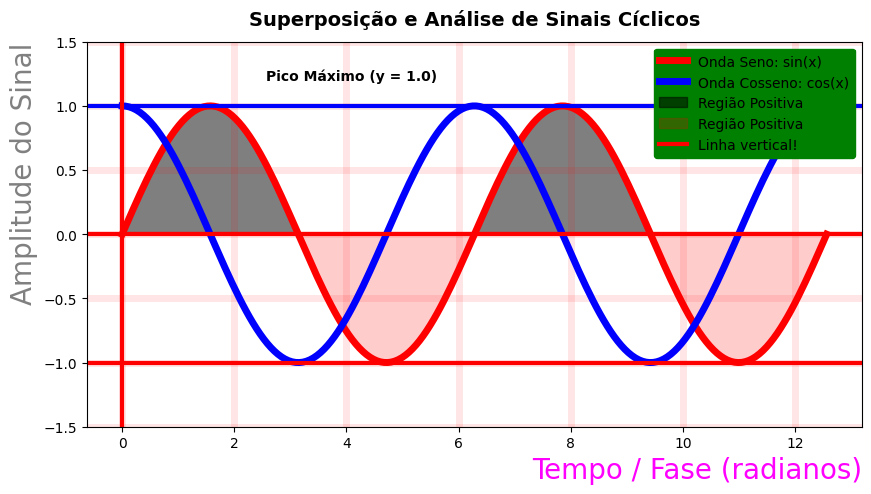

In [140]:
# Exemplo Prático: Simulação de Funções Trigonométricas e Área Sombreada
x = np.linspace(0, 4 * np.pi, 200)
onda_seno = np.sin(x)
onda_cosseno = np.cos(x)

fig, ax = plt.subplots(figsize=(10, 5))

# Plotando duas curvas com estilos distintos
ax.plot(x, onda_seno   , color='red' , linewidth=5, linestyle='-', label='Onda Seno: sin(x)')
ax.plot(x, onda_cosseno, color='blue', linewidth=5, linestyle='-', label='Onda Cosseno: cos(x)')

# Preenchendo a área sob a curva do seno quando ela é positiva
ax.fill_between(x, onda_seno, 0, where=(onda_seno >= 0), color='black' , alpha=0.5, label='Região Positiva')
ax.fill_between(x, onda_seno, 0, where=(onda_seno < 0), color='red', alpha=0.2, label='Região Positiva')

# Linha horizontal de referência no zero
ax.axhline(0, color='red', linestyle='-', linewidth=3)
ax.axhline(1, color='blue', linestyle='-', linewidth=3)
ax.axhline(-1, color='red', linestyle='-', linewidth=3)
ax.axvline(0, color='red', linestyle='-', linewidth=3, label='Linha vertical!')


# Adicionando uma anotação apontando para o pico máximo do seno
ax.annotate('Pico Máximo (y = 1.0)', xy=(np.pi, 1.0), 
            xytext=(np.pi / 2 + 1, 1.2),
            fontsize=10, 
            fontweight='bold'
           )

# Configurações de layout e títulos
ax.set_title('Superposição e Análise de Sinais Cíclicos', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Tempo / Fase (radianos)', fontsize=20, loc='right', color='magenta')
ax.set_ylabel('Amplitude do Sinal', fontsize=20, loc= 'top', color='gray')
ax.set_ylim(-1.5, 1.5)
ax.grid(True, linestyle='-', alpha=0.1, color='red', linewidth=5)
ax.legend(loc='upper right', frameon=True, shadow=False , facecolor="green", edgecolor="green", framealpha=1)

plt.show()


## 3. Gráficos de Dispersão (`ax.scatter`) e Análise Multidimensional

O gráfico de dispersão (*scatter plot*) é a ferramenta ideal para analisar a **relação e correlação entre duas variáveis quantitativas contínuas**.

O grande diferencial do `ax.scatter` em relação ao `ax.plot` é que ele permite mapear **4 dimensões de informação** simultaneamente em um plano 2D:
1. **Posição no Eixo X**: 1ª variável contínua (ex: Horas de Estudo).
2. **Posição no Eixo Y**: 2ª variável contínua (ex: Nota Final na Prova).
3. **Tamanho do Ponto (`s`)**: 3ª variável (ex: Quantidade de Exercícios Resolvidos).
4. **Cor do Ponto (`c` + `cmap`)**: 4ª variável contínua ou categórica (ex: Nível de Frequência ou Idade).

### 🌈 Mapas de Cores Úteis (*Colormaps*):
* `'viridis'`, `'plasma'`, `'inferno'`, `'magma'` (perceptualmente uniformes).
* `'coolwarm'`, `'bwr'`, `'seismic'` (divergentes, ótimos para valores positivos/negativos ou acima/abaixo da média).
* `'Blues'`, `'Greens'`, `'Reds'` (sequenciais).


In [141]:
# Exemplo Prático: Desempenho de Estudantes (4 Dimensões em 2D)
np.random.seed(512)
n_alunos = 60


In [147]:
horas_estudo    = np.random.uniform(2, 20, n_alunos)
print(horas_estudo)

[ 6.47627443  7.03029717 11.26096068  8.5522873   9.37718609 19.80889512
 11.90758712  3.36982815 19.46509641  4.1481285  16.94722446 19.11940585
 12.11978819 16.43249439  9.71945392  3.79312132 11.28600617  3.22087053
 13.019983    7.16523364  9.01614396 16.57790591  3.9290013  13.72066912
 17.59639351 18.2069852  19.44696607  2.05257725 16.57380969  4.96631641
 10.66289115  5.87346481 12.5104932  11.58806408  3.45710185  4.90941364
  6.96446872 13.13959987 18.64147536  5.67124472  4.98216403  2.27612221
 10.7345704  12.41158433 10.81324643 17.57346151  5.6151821   3.30039536
  3.40254062  6.26756833  6.57316218  6.31004027  5.30885256  9.04634139
 11.42704692  8.11804891  9.67796801  9.28845306  4.91343384 15.97569958]


In [151]:
notas = 3.0 + 0.35 * horas_estudo + np.random.normal(0, 1.0, n_alunos)
# Nota correlacionada com as horas de estudo + ruído aleatório
notas           = np.clip(notas, 0, 10)
print(max(notas))

10.0


In [152]:




exercicios_feitos = np.random.randint(10, 100, n_alunos)  # Tamanho do ponto
presenca_percent = np.random.uniform(60, 100, n_alunos)   # Cor do ponto

In [153]:
exercicios_feitos

array([74, 10, 98, 44, 49, 83, 58, 88, 52, 66, 46, 63, 68, 97, 55, 35, 39,
       61, 85, 80, 18, 70, 21, 25, 83, 89, 62, 29, 51, 90, 21, 62, 53, 99,
       33, 51, 86, 40, 27, 32, 78, 66, 99, 23, 26, 65, 77, 80, 38, 91, 59,
       15, 54, 60, 73, 72, 32, 93, 90, 32])

In [154]:
presenca_percent

array([86.90002378, 77.69815677, 65.41881241, 80.42378226, 81.79505227,
       94.56776511, 84.15948419, 79.53177767, 93.52538317, 83.45969707,
       64.92434686, 74.19346189, 64.56295155, 80.33216208, 92.51434168,
       98.71025367, 97.38651985, 81.18761237, 71.67367084, 75.52431525,
       95.07803048, 87.45884226, 78.24843559, 78.12141344, 79.75354665,
       91.38981025, 73.99536187, 79.47866833, 72.63132203, 85.92840703,
       87.78806746, 69.69104339, 71.23282729, 79.51479646, 75.41491657,
       61.23394244, 71.68945912, 76.88426382, 91.17000642, 97.3338076 ,
       65.10437916, 96.87717866, 69.24032725, 93.84348413, 88.95881957,
       75.2321334 , 80.82016919, 71.83147056, 73.34734214, 61.98663075,
       98.58802983, 99.93697877, 77.96012695, 61.90459317, 74.80386219,
       65.9826119 , 82.85676604, 83.86029222, 62.83167957, 93.52737331])

In [156]:
aluno= 10
print(f"Aluno {aluno}, nota = {notas[aluno]}, horas de estudo = {horas_estudo[aluno]}, presença = {presenca_percent[aluno]}, quant. feito = {exercicios_feitos[aluno]}, ")

Aluno 10, nota = 9.531586758885775, horas de estudo = 16.94722445506218, presença = 64.92434686211085, quant. feito = 46, 


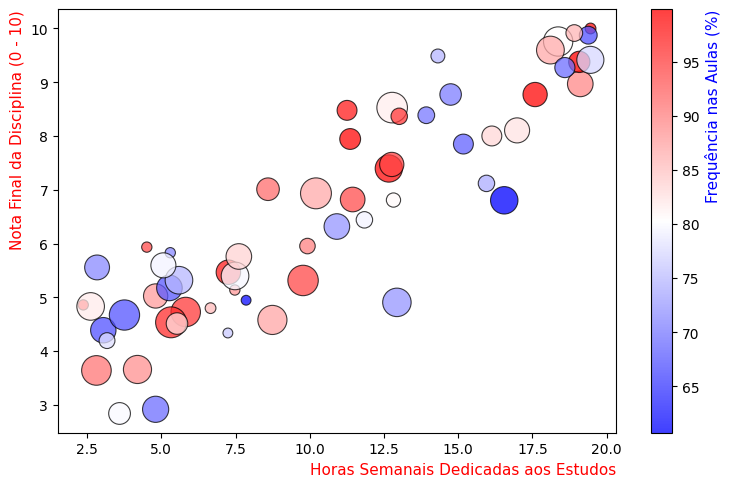

In [168]:
# Exemplo Prático: Desempenho de Estudantes (4 Dimensões em 2D)
np.random.seed(42)
n_alunos = 60

horas_estudo    = np.random.uniform(2, 20, n_alunos)
# Nota correlacionada com as horas de estudo + ruído aleatório
notas           = np.clip(3.0 + 0.35 * horas_estudo + np.random.normal(0, 1.0, n_alunos), 0, 10)
exercicios_feitos = np.random.randint(10, 100, n_alunos)  # Tamanho do ponto
presenca_percent = np.random.uniform(60, 100, n_alunos)   # Cor do ponto

fig, ax = plt.subplots(figsize=(9, 5.5))

# Criando o scatter plot multidimensional
scatter = ax.scatter(
    horas_estudo, # x
    notas, # y
    s=exercicios_feitos*5,      # Tamanho proporcional aos exercícios
    c=presenca_percent,          # Cor mapeada pela frequência (%)
    cmap='bwr',              # Paleta de cores
    alpha=0.75,                  # Transparência para pontos sobrepostos
    edgecolors='black',          # Borda dos círculos
    linewidth=0.8
)

# Adicionando a barra de cores (Colorbar)
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label('Frequência nas Aulas (%)', fontsize=11, loc='top', color='blue')

# Linha de corte / aprovação
#ax.axhline(5.0, color='#e74c3c', linestyle='--', linewidth=1.5, label='Nota Mínima de Aprovação (5.0)')

#ax.set_title('Correlação: Horas de Estudo x Nota Final', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Horas Semanais Dedicadas aos Estudos', fontsize=11, color='red', loc='right')
ax.set_ylabel('Nota Final da Disciplina (0 - 10)', fontsize=11, color='red', loc='top')
#ax.grid(True, linestyle=':', alpha=0.6)
#ax.legend(loc='lower right')

plt.show()


## 4. Gráficos de Barras (`ax.bar` e `ax.barh`) para Dados Categóricos

Quando queremos comparar quantidades, faturamentos, contagens ou médias entre **categorias discretas**, o gráfico de barras é a escolha mais eficiente e direta.

### 📊 Tipos de Gráficos de Barras:
1. **Barras Verticais (`ax.bar`)**: Padrão quando há poucas categorias ou quando os nomes são curtos.
2. **Barras Horizontais (`ax.barh`)**: Excelente quando há muitas categorias ou quando os rótulos de texto são longos (evita que os nomes fiquem inclinados ou sobrepostos).
3. **Barras com Rótulos de Dados (`ax.bar_label`)**: Exibe o valor exato no topo de cada barra com formatação profissional (ex: valores em $R\$$ ou porcentagens).


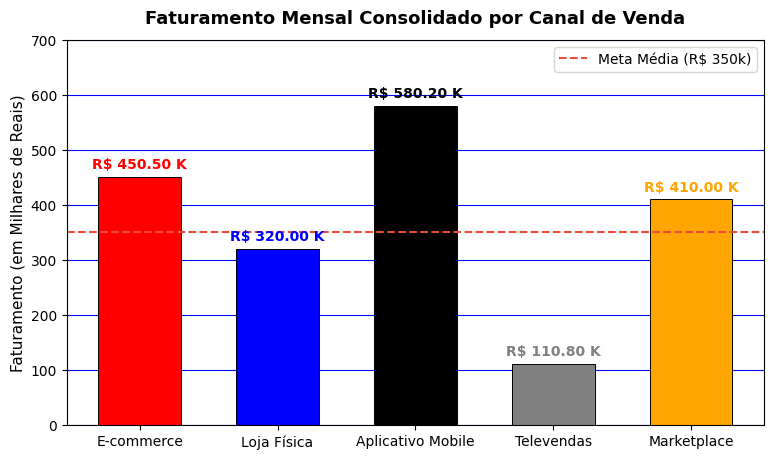

In [197]:
# Exemplo Prático: Faturamento por Canal de Atendimento com Rótulos
canais = ['E-commerce', 'Loja Física', 'Aplicativo Mobile', 'Televendas', 'Marketplace']
vendas_milhares = [450.5, 320.0, 580.2, 110.8, 410.0]
cores = ['#3498db', '#95a5a6', '#2ecc71', '#e67e22', '#9b59b6']
cores = ['red', 'blue', 'black', 'gray','orange']

fig, ax = plt.subplots(figsize=(9, 5))



# Criando as barras verticais
barras = ax.bar(canais, vendas_milhares, color=cores, edgecolor='black', linewidth=0.7, width=0.6)

# Adicionando rótulos de valores em cima das barras automaticamente
bar_labels = ax.bar_label(barras, fmt='R$ %1.2f K' , padding=4, fontsize=10, fontweight='bold', color='red')

# 3. O loop vincula a barra à sua respectiva label para igualar as cores
for idx , bar_label in enumerate(bar_labels):
    bar_label.set_color(cores[idx])

ax.grid( linestyle='-', alpha=1, axis='y', color='blue')


# Linha de meta de faturamento médio
meta = 350.0
ax.axhline(meta, color='#e74c3c', linestyle='--', linewidth=1.5, label=f'Meta Média (R$ {meta:.0f}k)')

ax.set_title('Faturamento Mensal Consolidado por Canal de Venda', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Faturamento (em Milhares de Reais)', fontsize=11)
ax.set_ylim(0, 700)
ax.legend(loc='upper right')
ax.set_axisbelow(True)
#plt.show()


## 5. Histogramas (`ax.hist`) e Distribuição de Frequência

O **histograma** divide uma variável numérica contínua em pequenos intervalos chamados **`bins`** (ou classes) e conta quantas observações caem dentro de cada intervalo.

Ele é fundamental para responder perguntas como:
* Qual é o valor mais comum (*moda*) dos meus dados?
* Os dados seguem uma distribuição Normal (em formato de sino)?
* Há assimetria à direita (valores muito altos raros) ou à esquerda?
* Onde se concentram a média e a mediana?

### ⚙️ Principais Parâmetros do `ax.hist`:
* `bins`: Número de intervalos (ex: `bins=20`) ou lista com os limites exatos (ex: `bins=[0, 10, 20, 30]`).
* `density=True`: Normaliza a área do histograma para somar 1.0 (transformando contagens brutas em densidade de probabilidade).
* `color` e `edgecolor`: Cor das barras e das divisórias.
* `cumulative=True`: Constrói a distribuição cumulativa.


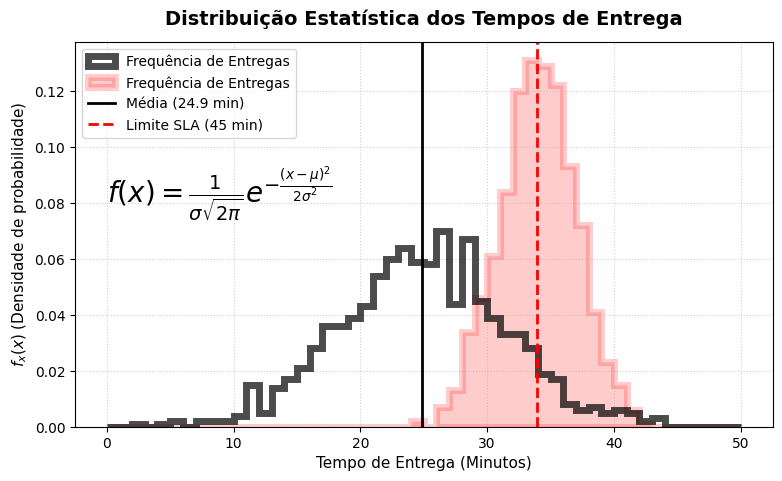

In [254]:
# Exemplo Prático: Análise da Distribuição de Tempos de Entrega (Delivery)
np.random.seed(10)
# Simulando 1000 entregas com média de 32 minutos e desvio de 7 minutos
tempos_entrega_1 = np.random.normal(loc=25, scale=7, size=1000)

tempos_entrega_2 = np.random.normal(loc=34, scale=3, size=1000)



media_1 = np.mean(tempos_entrega_1)
media_2 = np.mean(tempos_entrega_2)

fig, ax = plt.subplots(figsize=(9, 5))

# Criando o histograma com 25 bins
hist_1 = ax.hist(
    tempos_entrega_1, 
    range = (0, 50),
    bins=50, 
    #color='red', 
    histtype='step',
    edgecolor='black', 
    alpha=0.7, 
    linewidth=5,
    label='Frequência de Entregas',
    density=True,
)

hist_2 = ax.hist(
    tempos_entrega_2, 
    range = (0, 50),
    bins=50, 
    #color='red', 
    histtype='stepfilled',
    edgecolor='red',
    facecolor='red',
    linewidth=5,
    alpha=0.2, 
    label='Frequência de Entregas',
    density=True
)


# Adicionando linhas de referência da Média e Limite SLA (45 min)
ax.axvline(media_1, color='black', linestyle='-', linewidth=2, label=f'Média ({media:.1f} min)')
ax.axvline(media_2, color='red', linestyle='--', linewidth=2, label='Limite SLA (45 min)')

ax.set_title('Distribuição Estatística dos Tempos de Entrega', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Tempo de Entrega (Minutos)', fontsize=11)
#ax.set_ylabel('Quantidade de Pedidos', fontsize=11)

ax.set_ylabel('$f_x(x)$ (Densidade de probabilidade)', fontsize=11)


# 1. Adicionado o 'r' e removido o fontweight do dicionário direto
eq = r"$f(x) = \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$"

ax.annotate(eq, 
            xy=(0, 0),         # Ponto para onde a seta apontaria (se houvesse uma)
            xytext=(0, 0.08), # Posição real do TEXTO (ajuste conforme os eixos do seu gráfico)
            fontsize=20
           )

ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left')

plt.show()


## 6. Múltiplos Subgráficos (*Dashboards* com `plt.subplots`)

Em projetos reais, raramente mostramos apenas um gráfico isolado. O padrão profissional é construir **painéis visuais integrados (*dashboards*)** onde múltiplos gráficos complementares são exibidos lado a lado em uma mesma figura.

### 🎛️ Como Funciona o `plt.subplots(nrows, ncols)`:
* `nrows`: Número de linhas de gráficos.
* `ncols`: Número de colunas de gráficos.
* Retorna uma tupla `(fig, axes)`:
  * Se for $1 	imes 1$: `axes` é um único objeto `Axes`.
  * Se for $1 	imes N$ ou $N 	imes 1$: `axes` é um array NumPy 1D indexável com `axes[0], axes[1], ...`.
  * Se for $N 	imes M$: `axes` é uma matriz NumPy 2D indexável com `axes[linha, coluna]`.

> 💡 **Dica de Ouro**: Sempre utilize `plt.tight_layout()` ao final para que o Matplotlib recalcule os espaços automáticos e evite sobreposição de textos e rótulos entre os subgráficos!


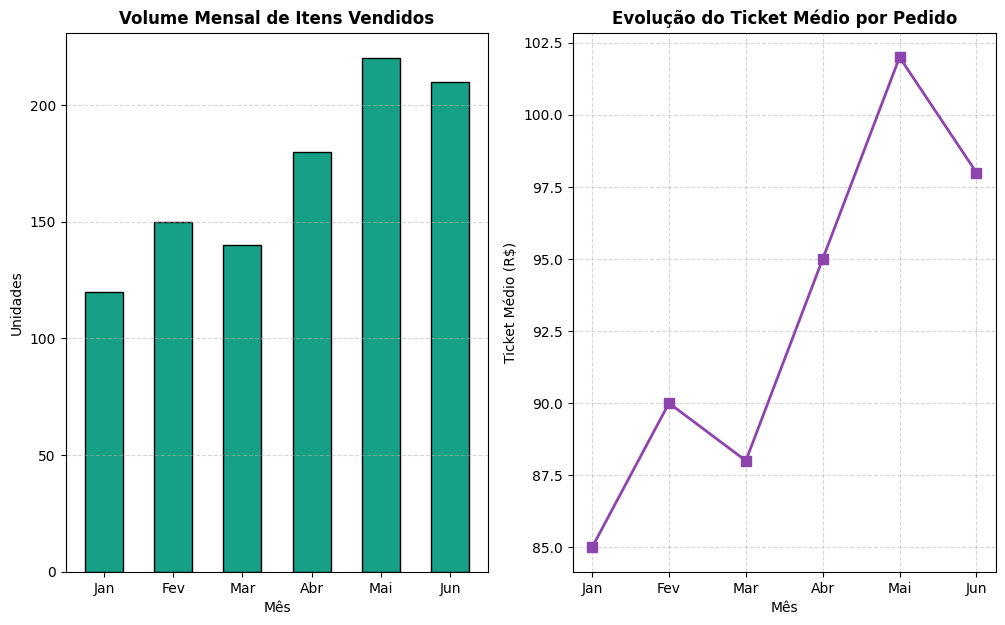

In [267]:
# Exemplo Prático: Painel 1x2 Comparativo (Vendas vs Faturamento)
meses = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun']
unidades_vendidas = [120, 150, 140, 180, 220, 210]
ticket_medio = [85.0, 90.0, 88.0, 95.0, 102.0, 98.0]

# Criando grade de 1 linha e 2 colunas
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 7))


# Subgráfico 1: Volume de Unidades Vendidas (Barras)
axes[0].bar(meses, unidades_vendidas, color='#16a085', edgecolor='black', width=0.55)
axes[0].set_title('Volume Mensal de Itens Vendidos', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Mês')
axes[0].set_ylabel('Unidades')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Subgráfico 2: Evolução do Ticket Médio (Linha com Marcadores)
axes[1].plot(meses, ticket_medio, color='#8e44ad', marker='s', linewidth=2, markersize=7)
axes[1].set_title('Evolução do Ticket Médio por Pedido', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Mês')
axes[1].set_ylabel('Ticket Médio (R$)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Ajuste automático de layout para evitar sobreposições
#plt.tight_layout()
plt.show()


---

## 7. Exercícios Práticos Resolvidos

Chegou a hora de colocar a mão na massa! A seguir, você resolverá 6 problemas práticos com cenários reais de **jogos, física, monitoramento de energia, estatística de eSports, e-commerce, mercado imobiliário e aplicativos de saúde**.

Para cada exercício:
1. Leia o contexto e o enunciado detalhado.
2. Complete a função na **Célula de Prática** (onde está o `pass`), atendendo a todos os requisitos visuais solicitados.
3. Compare seu resultado com a **Célula de Resposta Comentada**.

---


### 🎮 Exercício 1 (Física & Jogos): Trajetória Balística de Projéteis

**Contexto:**
Em um jogo de estratégia balística (estilo *Worms* ou *Angry Birds*), um canhão dispara projéteis com velocidade inicial fixa $v_0 = 30\text{ m/s}$, sob aceleração da gravidade $g = 9.81\text{ m/s}^2$. A equação que descreve a altura $y(x)$ do projétil em função da distância horizontal percorrida $x$ para um ângulo de lançamento $\theta$ (em radianos) é dada por:

$$y(x) = x \cdot \tan(\theta) - \frac{g \cdot x^2}{2 \cdot v_0^2 \cdot \cos^2(\theta)}$$

O alcance horizontal máximo $X_{\text{max}}$ onde o projétil atinge o chão ($y = 0$) é:
$$X_{\text{max}} = \frac{v_0^2 \cdot \sin(2\theta)}{g}$$

**Objetivo:**
Crie a função `plotar_trajetorias_balisticas(v0: float, angulos_graus: list[float], g: float = 9.81) -> tuple[plt.Figure, plt.Axes]` que:
1. Cria uma figura de tamanho `(9, 5)`.
2. Para cada ângulo em `angulos_graus`, converte o ângulo para radianos com `np.radians()`, calcula $X_{\text{max}}$, gera 100 pontos de $x$ entre $0$ e $X_{\text{max}}$ com `np.linspace()` e calcula as alturas $y(x)$.
3. Plota a curva de cada ângulo com cores distintas e espessura `linewidth=2`, adicionando o rótulo `f'Ângulo {theta}°'`.
4. Marca o ponto de altura máxima de cada curva com um marcador `'o'` de destaque.
5. Define o título `'Simulação Balística de Lançamento de Projéteis'`, rótulo do eixo X `'Distância Horizontal (m)'`, rótulo do eixo Y `'Altura (m)'`, limite mínimo $y \ge 0$, grade e legenda.
6. Retorna a tupla `(fig, ax)`.

---


In [26]:
# Célula de Prática: Exercício 1
import matplotlib.pyplot as plt
import numpy as np

def plotar_trajetorias_balisticas(v0: float, angulos_graus: list[float], g: float = 9.81) -> tuple[plt.Figure, plt.Axes]:
    """Gera um gráfico comparativo da trajetória balística de projéteis para múltiplos ângulos.

    Parâmetros:
        v0 (float): Velocidade inicial em m/s.
        angulos_graus (list[float]): Lista com os ângulos de disparo em graus.
        g (float): Aceleração da gravidade em m/s² (padrão 9.81).

    Retorno:
        tuple[plt.Figure, plt.Axes]: Objetos Figure e Axes do Matplotlib.
    """
    pass

# Exemplo de teste:
# fig, ax = plotar_trajetorias_balisticas(v0=30.0, angulos_graus=[15, 30, 45, 60, 75])
# plt.show()
#
# Elementos Visuais Esperados:
# - Curvas parabólicas iniciando em (0,0) e terminando em y=0.
# - Ângulo de 45° apresentando o maior alcance horizontal (~91.7 m).
# - Marcadores no ponto de altura máxima de cada curva.
# - Grade habilitada, título, eixos identificados e legenda no canto superior direito.


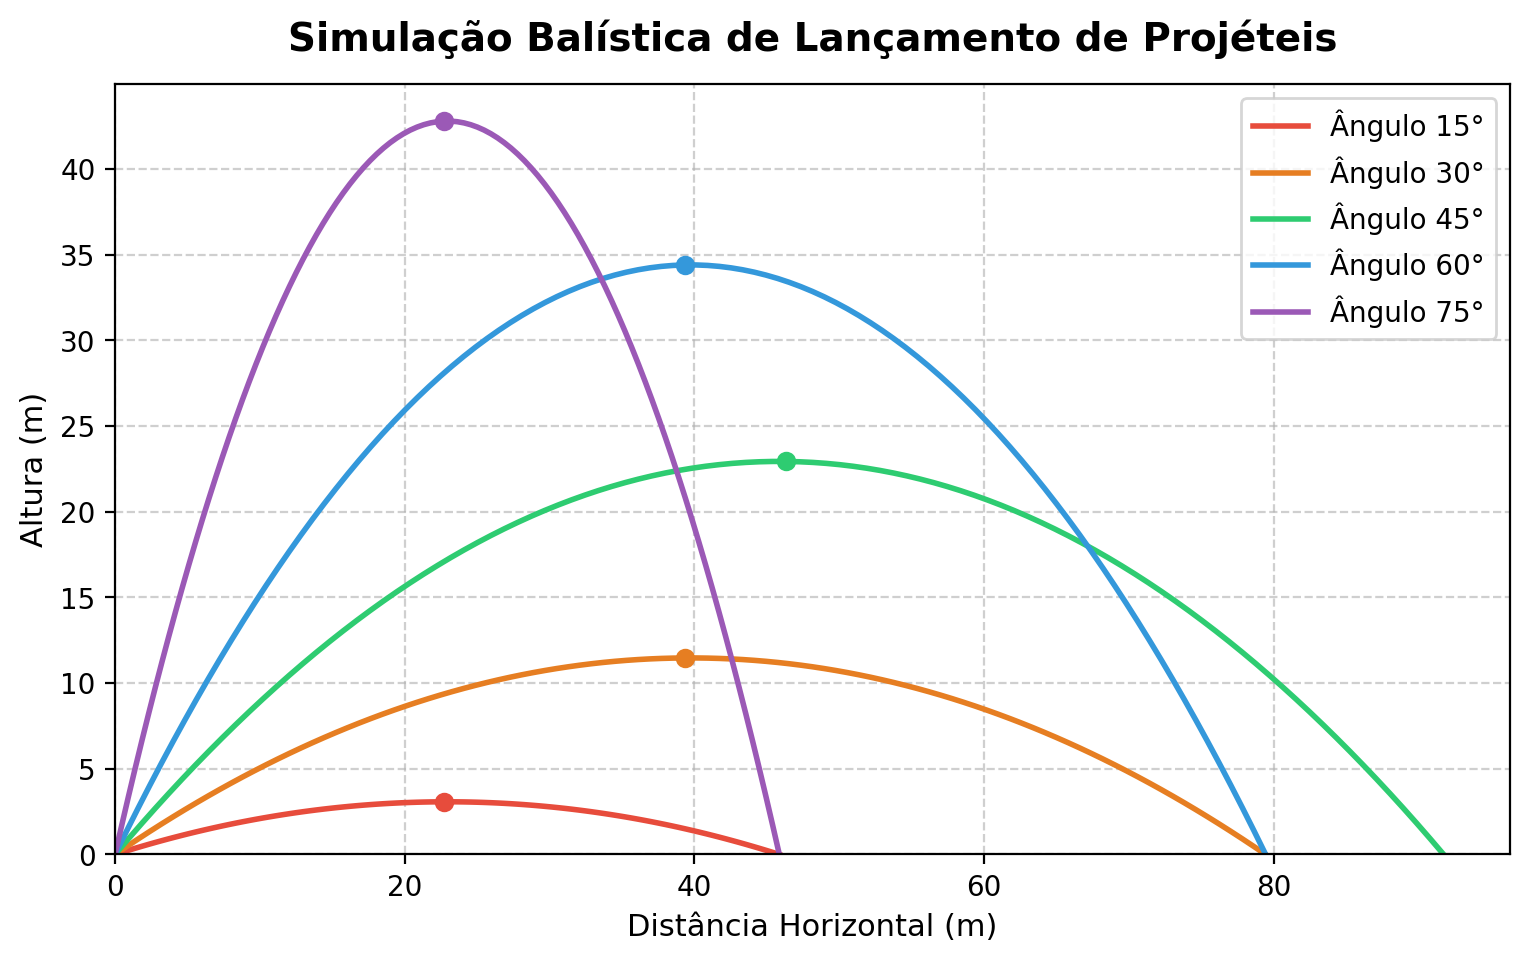

In [27]:
# Resposta Comentada: Exercício 1
import matplotlib.pyplot as plt
import numpy as np

def plotar_trajetorias_balisticas(v0: float, angulos_graus: list[float], g: float = 9.81) -> tuple[plt.Figure, plt.Axes]:
    # 1. Cria a estrutura da figura e do axes
    fig, ax = plt.subplots(figsize=(9, 5))
    
    # Paleta de cores para os ângulos
    cores = ['#e74c3c', '#e67e22', '#2ecc71', '#3498db', '#9b59b6']
    
    for i, angulo_deg in enumerate(angulos_graus):
        theta = np.radians(angulo_deg)
        
        # Alcance máximo no solo (y = 0)
        x_max = (v0**2 * np.sin(2 * theta)) / g
        
        # Vetor de posições x do disparo até o impacto
        x = np.linspace(0, x_max, 100)
        # Equação da trajetória balística y(x)
        y = x * np.tan(theta) - (g * x**2) / (2 * v0**2 * (np.cos(theta)**2))
        
        cor = cores[i % len(cores)]
        # Plota a trajetória contínua
        ax.plot(x, y, color=cor, linewidth=2, label=f'Ângulo {angulo_deg}°')
        
        # Ponto de altura máxima (vértice da parábola)
        idx_max = np.argmax(y)
        ax.plot(x[idx_max], y[idx_max], marker='o', color=cor, markersize=6)
    
    # 2. Configurações visuais e legendas
    ax.set_title('Simulação Balística de Lançamento de Projéteis', fontsize=14, fontweight='bold', pad=12)
    ax.set_xlabel('Distância Horizontal (m)', fontsize=11)
    ax.set_ylabel('Altura (m)', fontsize=11)
    ax.set_ylim(bottom=0)
    ax.set_xlim(left=0)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper right', frameon=True)
    
    return fig, ax

# Executando o teste da solução:
fig, ax = plotar_trajetorias_balisticas(v0=30.0, angulos_graus=[15, 30, 45, 60, 75])
plt.show()


---

### ⚡ Exercício 2 (Séries Temporais & Smart Home): Monitoramento de Consumo de Energia Elétrica

**Contexto:**
Um medidor inteligente (*Smart Energy Meter*) registra o consumo diário de energia elétrica (em kWh) de uma residência ao longo dos 30 dias de um mês. A concessionária de energia estabelece um limite de consumo sustentável (média recomendada de $15.0\text{ kWh/dia}$). A família deseja um relatório gráfico que destaque os dias em que o consumo excedeu essa meta, com uma área sombreada de alerta em vermelho.

**Objetivo:**
Crie a função `plotar_consumo_energia(dias: list[int], consumo: list[float], meta_kwh: float = 15.0) -> tuple[plt.Figure, plt.Axes]` que:
1. Cria uma figura de tamanho `(10, 5)`.
2. Plota a linha de consumo diário em azul escuro (`#2980b9`) com marcadores circulares `'o'`, espessura `linewidth=2` e legenda `'Consumo Diário (kWh)'`.
3. Traça uma linha horizontal tracejada (`ax.axhline`) na altura de `meta_kwh` em vermelho (`#c0392b`) com legenda `f'Meta Sustentável ({meta_kwh} kWh)'`.
4. Utiliza `ax.fill_between` para colorir em vermelho claro (`#e74c3c`, `alpha=0.3`) a região entre o consumo e a meta **apenas nos dias em que o consumo foi maior que a meta**.
5. Localiza o dia de maior consumo e adiciona uma anotação textual (`ax.annotate`) apontando para o pico com a mensagem `'Consumo Máximo'`.
6. Configura título, rótulos de eixos, limites, grade e retorna `(fig, ax)`.

---


In [28]:
# Célula de Prática: Exercício 2
import matplotlib.pyplot as plt
import numpy as np

def plotar_consumo_energia(dias: list[int], consumo: list[float], meta_kwh: float = 15.0) -> tuple[plt.Figure, plt.Axes]:
    """Plota a série temporal de consumo de energia destacando os períodos acima da meta recomendada.

    Parâmetros:
        dias (list[int]): Lista com os dias do mês (1 a 30).
        consumo (list[float]): Consumo registrado em cada dia em kWh.
        meta_kwh (float): Limite de consumo sustentável (padrão 15.0 kWh).

    Retorno:
        tuple[plt.Figure, plt.Axes]: Objetos Figure e Axes do Matplotlib.
    """
    pass

# Exemplo de teste:
# dias_mes = list(range(1, 31))
# consumo_simulado = [12.5, 14.0, 13.2, 16.8, 19.5, 21.0, 18.2, 14.5, 13.0, 15.2,
#                     17.8, 22.4, 20.1, 14.8, 13.5, 12.8, 14.2, 16.0, 18.5, 17.0,
#                     13.8, 12.5, 14.0, 15.5, 18.0, 23.5, 19.0, 14.2, 13.0, 12.8]
# fig, ax = plotar_consumo_energia(dias_mes, consumo_simulado, meta_kwh=15.0)
# plt.show()
#
# Elementos Visuais Esperados:
# - Linha temporal contínua com marcadores nos 30 dias.
# - Linha horizontal vermelha tracejada no valor 15.0 kWh.
# - Áreas sombreadas em vermelho acima de 15 kWh nos dias de pico.
# - Anotação indicando o pico máximo no dia 26 (23.5 kWh).


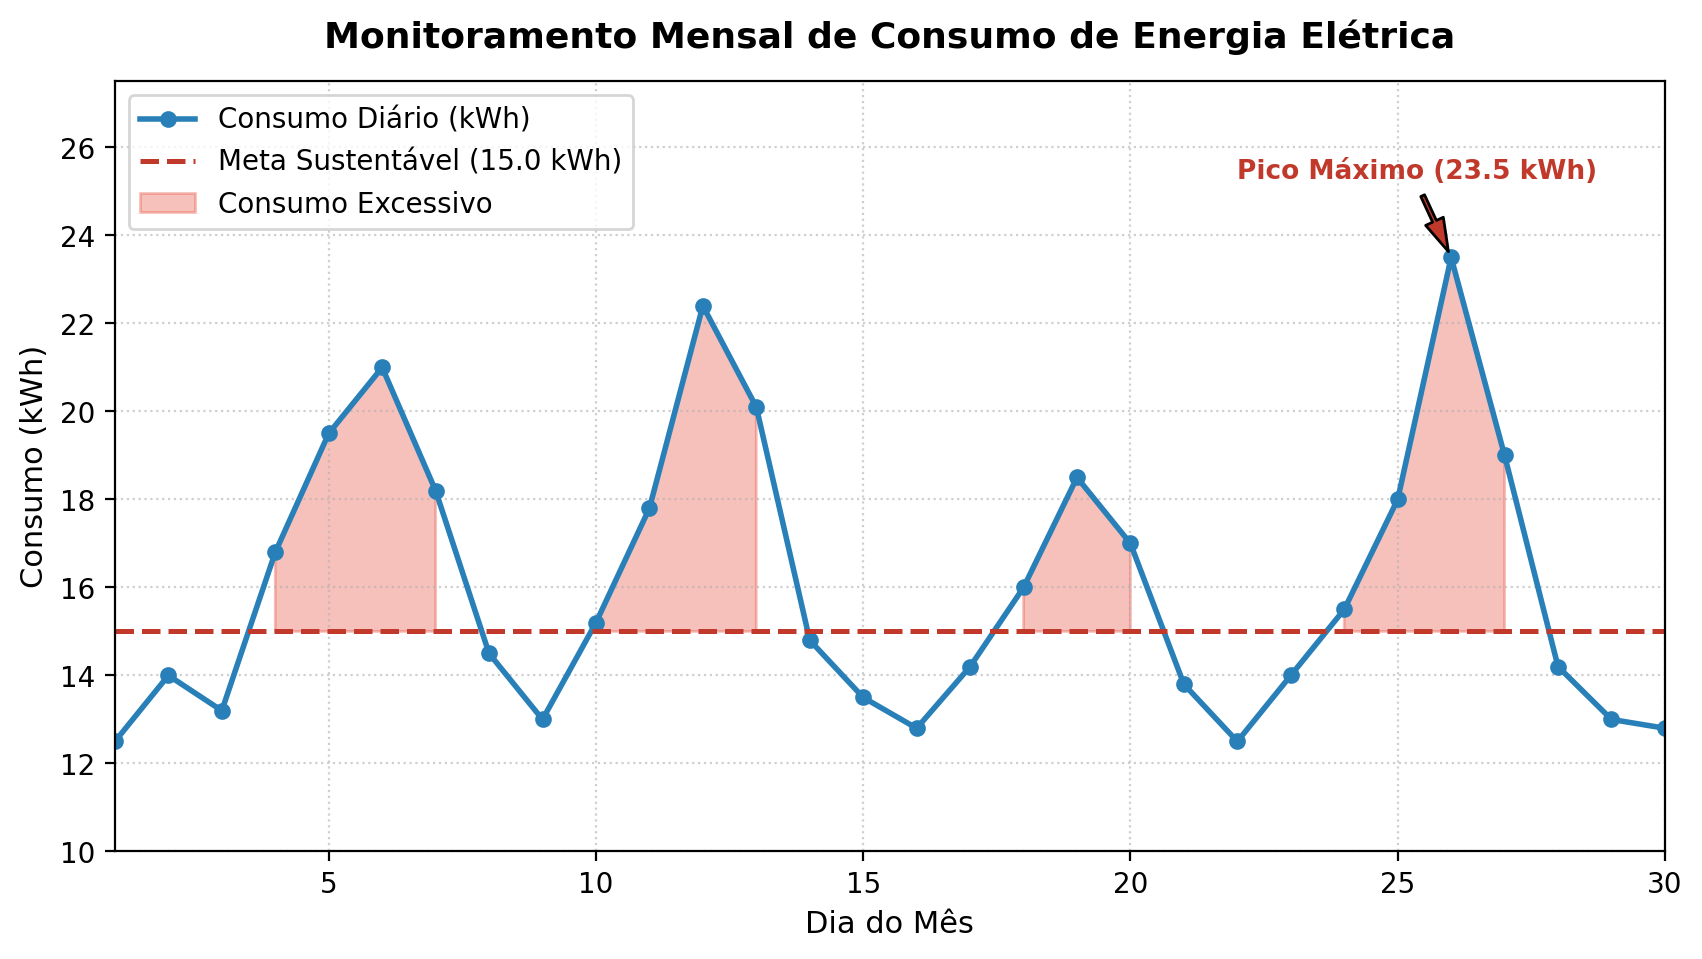

In [29]:
# Resposta Comentada: Exercício 2
import matplotlib.pyplot as plt
import numpy as np

def plotar_consumo_energia(dias: list[int], consumo: list[float], meta_kwh: float = 15.0) -> tuple[plt.Figure, plt.Axes]:
    dias_arr = np.array(dias)
    consumo_arr = np.array(consumo)
    
    fig, ax = plt.subplots(figsize=(10, 5))
    
    # 1. Plota a curva principal de consumo
    ax.plot(dias_arr, consumo_arr, color='#2980b9', marker='o', markersize=5, linewidth=2, label='Consumo Diário (kWh)')
    
    # 2. Linha horizontal da meta
    ax.axhline(meta_kwh, color='#c0392b', linestyle='--', linewidth=1.8, label=f'Meta Sustentável ({meta_kwh} kWh)')
    
    # 3. Preenchimento de alerta nas regiões acima da meta
    ax.fill_between(
        dias_arr, 
        consumo_arr, 
        meta_kwh, 
        where=(consumo_arr > meta_kwh), 
        color='#e74c3c', 
        alpha=0.35, 
        label='Consumo Excessivo'
    )
    
    # 4. Anotação do consumo máximo
    idx_pico = np.argmax(consumo_arr)
    dia_pico = dias_arr[idx_pico]
    valor_pico = consumo_arr[idx_pico]
    
    ax.annotate(
        f'Pico Máximo ({valor_pico:.1f} kWh)',
        xy=(dia_pico, valor_pico),
        xytext=(dia_pico - 4, valor_pico + 1.8),
        arrowprops=dict(facecolor='#c0392b', shrink=0.08, width=1.5, headwidth=7),
        fontsize=9.5,
        fontweight='bold',
        color='#c0392b'
    )
    
    # 5. Títulos e formatação dos eixos
    ax.set_title('Monitoramento Mensal de Consumo de Energia Elétrica', fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Dia do Mês', fontsize=11)
    ax.set_ylabel('Consumo (kWh)', fontsize=11)
    ax.set_xlim(1, len(dias))
    ax.set_ylim(10, max(consumo_arr) + 4)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', frameon=True)
    
    return fig, ax

# Executando o teste da solução:
dias_mes = list(range(1, 31))
consumo_simulado = [12.5, 14.0, 13.2, 16.8, 19.5, 21.0, 18.2, 14.5, 13.0, 15.2,
                    17.8, 22.4, 20.1, 14.8, 13.5, 12.8, 14.2, 16.0, 18.5, 17.0,
                    13.8, 12.5, 14.0, 15.5, 18.0, 23.5, 19.0, 14.2, 13.0, 12.8]
fig, ax = plotar_consumo_energia(dias_mes, consumo_simulado, meta_kwh=15.0)
plt.show()


---

### 🎯 Exercício 3 (Estatística & Jogos): Histograma Comparativo de Latência de Redes (Ping)

**Contexto:**
Um time de eSports realizou testes de conectividade coletando 400 amostras de ping (em milissegundos - ms) conectando-se a dois servidores:
* **Servidor Brasil (São Paulo)**: Baixa latência com distribuição concentrada ($\mu = 25\text{ ms}, \sigma = 5\text{ ms}$).
* **Servidor Internacional (EUA)**: Maior latência e maior variabilidade ($\mu = 135\text{ ms}, \sigma = 18\text{ ms}$).

Para avaliar a estabilidade da conexão para o próximo torneio, a equipe técnica precisa de um gráfico com histogramas comparativos sobrepostos e marcação visual das médias.

**Objetivo:**
Crie a função `plotar_histograma_latencia(ping_br: list[float], ping_eua: list[float]) -> tuple[plt.Figure, plt.Axes]` que:
1. Cria uma figura de tamanho `(9, 5)`.
2. Plota o histograma do `ping_br` com `bins=20`, cor verde (`#2ecc71`), transparência `alpha=0.6`, borda preta e legenda `'Servidor Brasil (SP)'`.
3. Plota o histograma do `ping_eua` com `bins=20`, cor laranja (`#e67e22`), transparência `alpha=0.6`, borda preta e legenda `'Servidor EUA (Miami)'`.
4. Traça linhas verticais (`ax.axvline`) indicando a média de cada servidor com estilo tracejado (`--`) e espessura `linewidth=2`.
5. Define título `'Distribuição de Latência (Ping) dos Servidores de Jogo'`, rótulo X `'Latência (ms)'`, rótulo Y `'Frequência de Pacotes'`, grade e legenda.
6. Retorna `(fig, ax)`.

---


In [30]:
# Célula de Prática: Exercício 3
import matplotlib.pyplot as plt
import numpy as np

def plotar_histograma_latencia(ping_br: list[float], ping_eua: list[float]) -> tuple[plt.Figure, plt.Axes]:
    """Plota histogramas sobrepostos comparando a latência de dois servidores de jogos.

    Parâmetros:
        ping_br (list[float]): Amostras de ping do servidor local (Brasil).
        ping_eua (list[float]): Amostras de ping do servidor internacional (EUA).

    Retorno:
        tuple[plt.Figure, plt.Axes]: Objetos Figure e Axes do Matplotlib.
    """
    pass

# Exemplo de teste:
# np.random.seed(42)
# amostras_br = np.random.normal(loc=25, scale=5, size=400).tolist()
# amostras_eua = np.random.normal(loc=135, scale=18, size=400).tolist()
# fig, ax = plotar_histograma_latencia(amostras_br, amostras_eua)
# plt.show()
#
# Elementos Visuais Esperados:
# - Dois blocos de histogramas bem separados (um em torno de 25 ms e outro em torno de 135 ms).
# - Barras com transparência permitindo visualização nítida.
# - Linhas verticais tracejadas nas médias correspondentes.
# - Legendas e títulos descritivos.


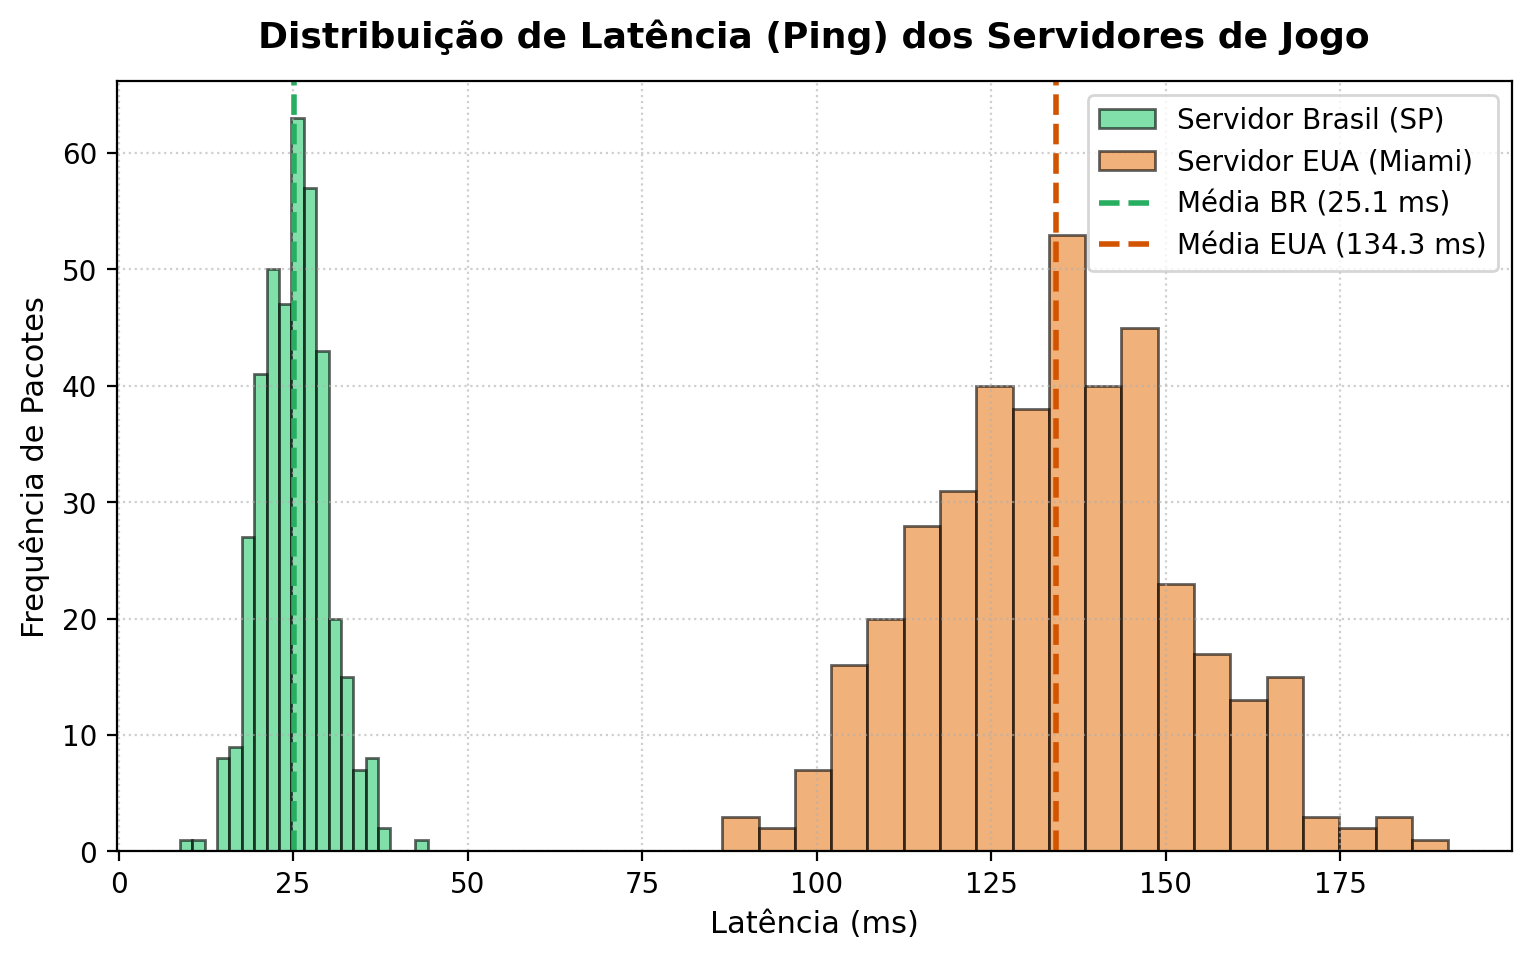

In [31]:
# Resposta Comentada: Exercício 3
import matplotlib.pyplot as plt
import numpy as np

def plotar_histograma_latencia(ping_br: list[float], ping_eua: list[float]) -> tuple[plt.Figure, plt.Axes]:
    arr_br = np.array(ping_br)
    arr_eua = np.array(ping_eua)
    
    fig, ax = plt.subplots(figsize=(9, 5))
    
    # 1. Histogramas sobrepostos com alpha para transparência
    ax.hist(arr_br, bins=20, color='#2ecc71', edgecolor='black', alpha=0.6, label='Servidor Brasil (SP)')
    ax.hist(arr_eua, bins=20, color='#e67e22', edgecolor='black', alpha=0.6, label='Servidor EUA (Miami)')
    
    # 2. Cálculo e desenho das linhas médias
    media_br = np.mean(arr_br)
    media_eua = np.mean(arr_eua)
    
    ax.axvline(media_br, color='#27ae60', linestyle='--', linewidth=2, label=f'Média BR ({media_br:.1f} ms)')
    ax.axvline(media_eua, color='#d35400', linestyle='--', linewidth=2, label=f'Média EUA ({media_eua:.1f} ms)')
    
    # 3. Formatações e rótulos
    ax.set_title('Distribuição de Latência (Ping) dos Servidores de Jogo', fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Latência (ms)', fontsize=11)
    ax.set_ylabel('Frequência de Pacotes', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right', frameon=True)
    
    return fig, ax

# Executando o teste da solução:
np.random.seed(42)
amostras_br = np.random.normal(loc=25, scale=5, size=400).tolist()
amostras_eua = np.random.normal(loc=135, scale=18, size=400).tolist()
fig, ax = plotar_histograma_latencia(amostras_br, amostras_eua)
plt.show()


---

### 🛍️ Exercício 4 (E-commerce): Desempenho de Departamentos e Rótulos Automáticos

**Contexto:**
A diretoria de um grande e-commerce precisa apresentar aos investidores o faturamento mensal de 5 departamentos. Para facilitar a tomada de decisão rápida, a equipe de design exigiu que:
* Departamentos que **atingiram ou superaram a meta de R$ 300 mil** devem ter suas barras pintadas de **verde** (`#2ecc71`).
* Departamentos que **ficaram abaixo da meta** devem ser destacados em **vermelho** (`#e74c3c`).
* O valor exato em milhares de reais deve aparecer no topo de cada barra (`ax.bar_label`).
* Uma linha horizontal pontilhada deve demarcar a meta corporativa.

**Objetivo:**
Crie a função `plotar_desempenho_departamentos(departamentos: list[str], faturamentos_milhares: list[float], meta: float = 300.0) -> tuple[plt.Figure, plt.Axes]` que:
1. Cria uma figura de tamanho `(8.5, 5)`.
2. Define uma lista de cores dinamicamente: verde para faturamentos $\ge \text{meta}$ e vermelho para os menores.
3. Desenha o gráfico de barras verticais com bordas pretas sutis.
4. Adiciona rótulos no topo das barras com o formato `'R$ {valor:.1f}k'`.
5. Traça a linha horizontal da meta com `ax.axhline` e configura títulos, limites superiores e grade vertical.
6. Retorna `(fig, ax)`.

---


In [32]:
# Célula de Prática: Exercício 4
import matplotlib.pyplot as plt
import numpy as np

def plotar_desempenho_departamentos(departamentos: list[str], faturamentos_milhares: list[float], meta: float = 300.0) -> tuple[plt.Figure, plt.Axes]:
    """Gera um gráfico de barras com cores condicionais e rótulos de valores no topo.

    Parâmetros:
        departamentos (list[str]): Nomes dos departamentos da loja.
        faturamentos_milhares (list[float]): Faturamento de cada departamento em milhares de R$.
        meta (float): Meta mínima estipulada em milhares de R$ (padrão 300.0).

    Retorno:
        tuple[plt.Figure, plt.Axes]: Objetos Figure e Axes do Matplotlib.
    """
    pass

# Exemplo de teste:
# depts = ['Eletrônicos', 'Móveis', 'Moda', 'Livros', 'Beleza']
# faturamento = [420.5, 280.0, 350.2, 190.8, 310.0]
# fig, ax = plotar_desempenho_departamentos(depts, faturamento, meta=300.0)
# plt.show()
#
# Elementos Visuais Esperados:
# - Barras verdes para Eletrônicos, Moda e Beleza.
# - Barras vermelhas para Móveis e Livros.
# - Textos com 'R$ 420.5k', etc., centralizados no topo de cada barra.
# - Linha horizontal demarcando a meta de R$ 300k.


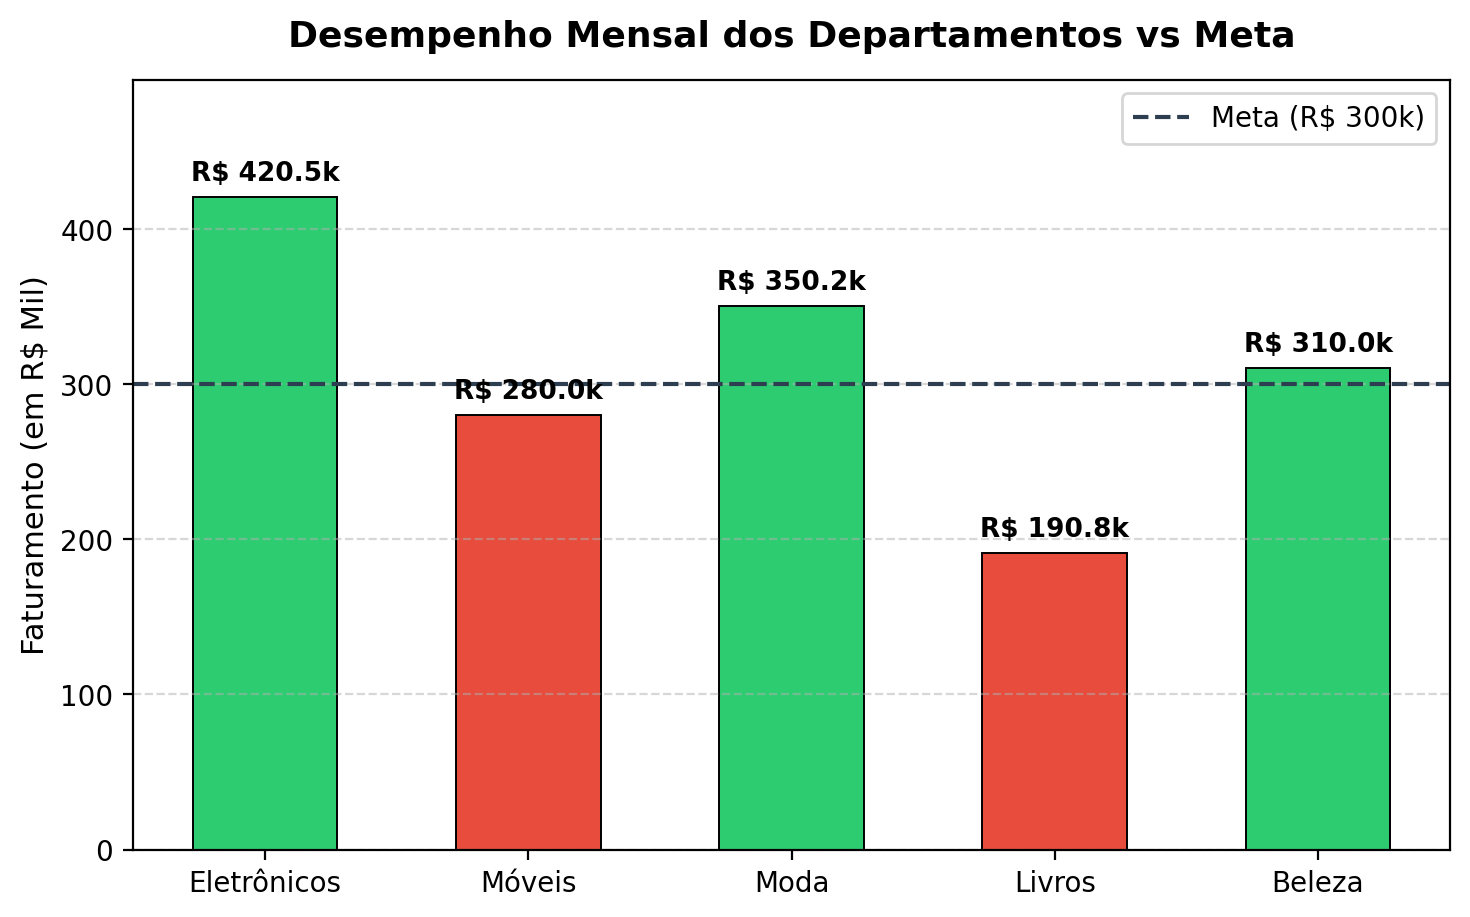

In [33]:
# Resposta Comentada: Exercício 4
import matplotlib.pyplot as plt
import numpy as np

def plotar_desempenho_departamentos(departamentos: list[str], faturamentos_milhares: list[float], meta: float = 300.0) -> tuple[plt.Figure, plt.Axes]:
    fig, ax = plt.subplots(figsize=(8.5, 5))
    
    # 1. Definição condicional de cores (verde se atingiu a meta, vermelho caso contrário)
    cores = ['#2ecc71' if valor >= meta else '#e74c3c' for valor in faturamentos_milhares]
    
    # 2. Desenha o gráfico de barras
    barras = ax.bar(departamentos, faturamentos_milhares, color=cores, edgecolor='black', linewidth=0.7, width=0.55)
    
    # 3. Adiciona rótulos com formatação de moeda no topo
    ax.bar_label(barras, fmt='R$ %.1fk', padding=4, fontsize=9.5, fontweight='bold')
    
    # 4. Linha de referência da meta
    ax.axhline(meta, color='#2c3e50', linestyle='--', linewidth=1.5, label=f'Meta (R$ {meta:.0f}k)')
    
    # 5. Ajustes de títulos e limites
    ax.set_title('Desempenho Mensal dos Departamentos vs Meta', fontsize=13, fontweight='bold', pad=12)
    ax.set_ylabel('Faturamento (em R$ Mil)', fontsize=11)
    ax.set_ylim(0, max(faturamentos_milhares) * 1.18)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', frameon=True)
    
    return fig, ax

# Executando o teste da solução:
depts = ['Eletrônicos', 'Móveis', 'Moda', 'Livros', 'Beleza']
faturamento = [420.5, 280.0, 350.2, 190.8, 310.0]
fig, ax = plotar_desempenho_departamentos(depts, faturamento, meta=300.0)
plt.show()


---

### 🏢 Exercício 5 (Mercado Imobiliário): Dispersão Multidimensional com Mapa de Cores

**Contexto:**
Uma agência imobiliária analisou centenas de apartamentos à venda em uma metrópole. A base de dados contém:
* **Área Privativa ($m^2$)**: Eixo X.
* **Preço de Venda (em Milhares de R$)**: Eixo Y.
* **Distância até a Estação de Metrô Mais Próxima (em km)**: Deve ser representada pela **cor dos pontos**. Apartamentos mais próximos do metrô ($0\text{ a }1\text{ km}$) são mais valorizados.
* **Quantidade de Vagas de Garagem (1 a 4 vagas)**: Deve modular o **tamanho dos pontos** ($s = \text{vagas} \times 40$).

**Objetivo:**
Crie a função `plotar_mercado_imobiliario(areas: list[float], precos: list[float], distancias_metro: list[float], vagas: list[int]) -> tuple[plt.Figure, plt.Axes]` que:
1. Cria uma figura de tamanho `(9.5, 5.5)`.
2. Plota o gráfico de dispersão com `ax.scatter`, passando `s = np.array(vagas) * 40`, `c = distancias_metro`, paleta `cmap='viridis_r'` (onde tons amarelos/claros indicam menor distância/melhor localização), transparência `alpha=0.8` e borda preta sutil.
3. Cria a barra de cores lateral associada ao gráfico com o rótulo `'Distância até o Metrô (km)'`.
4. Define título `'Análise de Precificação Imobiliária vs Localização'`, rótulos X e Y, grade e retorna `(fig, ax)`.

---


In [34]:
# Célula de Prática: Exercício 5
import matplotlib.pyplot as plt
import numpy as np

def plotar_mercado_imobiliario(areas: list[float], precos: list[float], distancias_metro: list[float], vagas: list[int]) -> tuple[plt.Figure, plt.Axes]:
    """Gera um gráfico de dispersão 4D correlacionando área, preço, distância do metrô e vagas.

    Parâmetros:
        areas (list[float]): Área do imóvel em m².
        precos (list[float]): Preço de venda em milhares de R$.
        distancias_metro (list[float]): Distância até a estação de metrô em km.
        vagas (list[int]): Número de vagas de garagem (1 a 4).

    Retorno:
        tuple[plt.Figure, plt.Axes]: Objetos Figure e Axes do Matplotlib.
    """
    pass

# Exemplo de teste:
# np.random.seed(15)
# n_imoveis = 80
# areas_sim = np.random.uniform(40, 180, n_imoveis).tolist()
# distancias_sim = np.random.uniform(0.2, 8.0, n_imoveis).tolist()
# vagas_sim = np.random.choice([1, 2, 3, 4], size=n_imoveis, p=[0.4, 0.35, 0.15, 0.1]).tolist()
# precos_sim = [area * 8.5 - dist * 25 + vaga * 40 + np.random.normal(0, 40) 
#               for area, dist, vaga in zip(areas_sim, distancias_sim, vagas_sim)]
#
# fig, ax = plotar_mercado_imobiliario(areas_sim, precos_sim, distancias_sim, vagas_sim)
# plt.show()
#
# Elementos Visuais Esperados:
# - Dispersão com tendência positiva (maior área -> maior preço).
# - Pontos com diferentes tamanhos representando 1 a 4 vagas.
# - Barra de cores vertical à direita indicando a proximidade do metrô.


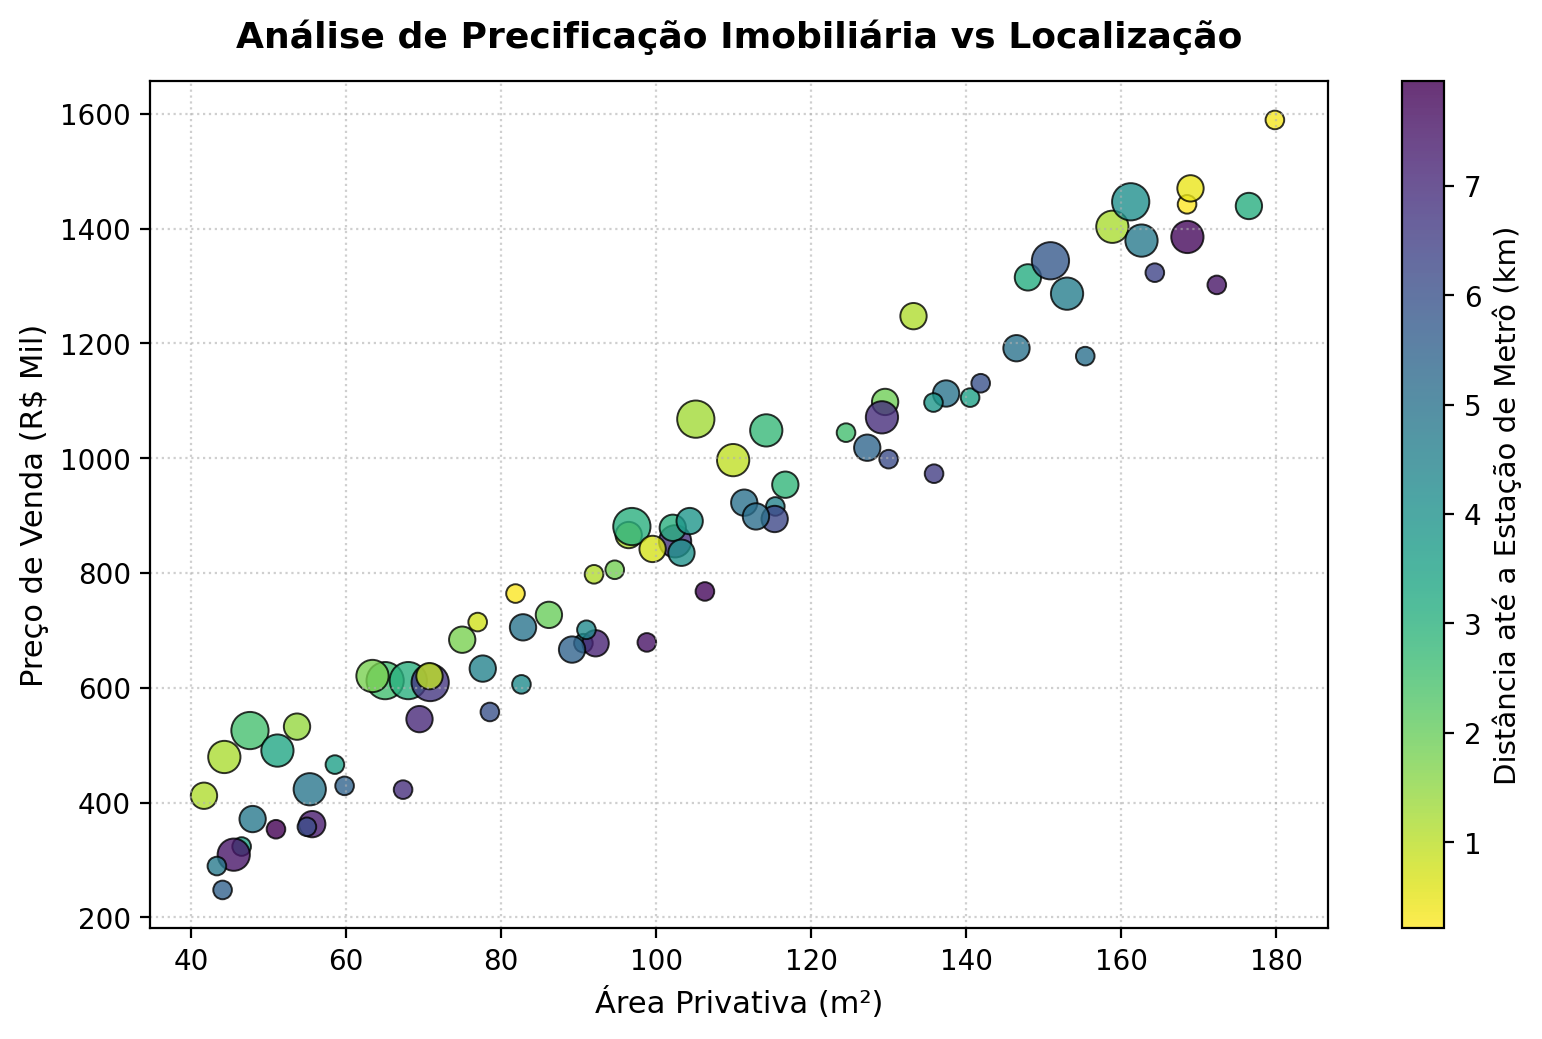

In [35]:
# Resposta Comentada: Exercício 5
import matplotlib.pyplot as plt
import numpy as np

def plotar_mercado_imobiliario(areas: list[float], precos: list[float], distancias_metro: list[float], vagas: list[int]) -> tuple[plt.Figure, plt.Axes]:
    fig, ax = plt.subplots(figsize=(9.5, 5.5))
    
    # 1. Converte listas para arrays NumPy
    areas_arr = np.array(areas)
    precos_arr = np.array(precos)
    dist_arr = np.array(distancias_metro)
    vagas_arr = np.array(vagas)
    
    # 2. Cria o gráfico de dispersão multidimensional
    scatter = ax.scatter(
        areas_arr,
        precos_arr,
        s=vagas_arr * 45,          # Tamanho proporcional às vagas
        c=dist_arr,               # Cor pela distância do metrô
        cmap='viridis_r',         # Paleta viridis invertida
        alpha=0.8,
        edgecolors='black',
        linewidth=0.7
    )
    
    # 3. Adiciona a barra de cores (Colorbar)
    cbar = fig.colorbar(scatter, ax=ax)
    cbar.set_label('Distância até a Estação de Metrô (km)', fontsize=10.5)
    
    # 4. Configurações de eixos e títulos
    ax.set_title('Análise de Precificação Imobiliária vs Localização', fontsize=13, fontweight='bold', pad=12)
    ax.set_xlabel('Área Privativa (m²)', fontsize=11)
    ax.set_ylabel('Preço de Venda (R$ Mil)', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    
    return fig, ax

# Executando o teste da solução:
np.random.seed(15)
n_imoveis = 80
areas_sim = np.random.uniform(40, 180, n_imoveis).tolist()
distancias_sim = np.random.uniform(0.2, 8.0, n_imoveis).tolist()
vagas_sim = np.random.choice([1, 2, 3, 4], size=n_imoveis, p=[0.4, 0.35, 0.15, 0.1]).tolist()
precos_sim = [area * 8.5 - dist * 25 + vaga * 40 + np.random.normal(0, 40) 
              for area, dist, vaga in zip(areas_sim, distancias_sim, vagas_sim)]

fig, ax = plotar_mercado_imobiliario(areas_sim, precos_sim, distancias_sim, vagas_sim)
plt.show()


---

### 🏃 Exercício 6 (Saúde & Esportes): Dashboard Integrado 2x2 com Múltiplos Subgráficos

**Contexto:**
Um aplicativo de monitoramento de atletas precisa gerar um relatório semanal unificado (*Dashboard*) que combine 4 métricas essenciais em uma grade $2 \times 2$:
1. **Subgráfico (0, 0) - Distância Corrida por Dia**: Gráfico de barras verticais (`ax.bar`) com cor ciano (`#1abc9c`) e rótulos nos topos das barras com os km percorridos.
2. **Subgráfico (0, 1) - Calorias Queimadas**: Gráfico de linha (`ax.plot`) em laranja (`#e67e22`) com marcadores `'o'` e área sombreada sob a curva (`ax.fill_between`) em laranja claro.
3. **Subgráfico (1, 0) - Frequência Cardíaca Média**: Gráfico de linha (`ax.plot`) em vermelho (`#e74c3c`) com linha horizontal pontilhada indicando a zona aeróbica recomendada de $145\text{ bpm}$.
4. **Subgráfico (1, 1) - Horas de Sono Diárias**: Gráfico de barras horizontais (`ax.barh`) em roxo (`#9b59b6`) com linha vertical de meta em $8.0\text{ horas}$.

**Objetivo:**
Crie a função `gerar_dashboard_fitness(dias: list[str], km: list[float], calorias: list[int], bpm: list[int], sono: list[float]) -> tuple[plt.Figure, np.ndarray]` que:
1. Cria uma figura com grade $2 \times 2$ e tamanho `(12, 8)` usando `plt.subplots(2, 2, figsize=(12, 8))`.
2. Constrói cada um dos 4 subgráficos descritos com seus respectivos títulos, eixos e grades.
3. Executa `plt.tight_layout()` para ajustar espaçamentos e evitar sobreposição.
4. Retorna a tupla `(fig, axes)`.

---


In [36]:
# Célula de Prática: Exercício 6
import matplotlib.pyplot as plt
import numpy as np

def gerar_dashboard_fitness(dias: list[str], km: list[float], calorias: list[int], bpm: list[int], sono: list[float]) -> tuple[plt.Figure, np.ndarray]:
    """Constrói um dashboard integrado 2x2 de métricas semanais de condicionamento físico.

    Parâmetros:
        dias (list[str]): Dias da semana (ex: ['Seg', 'Ter', ...]).
        km (list[float]): Distância percorrida em km por dia.
        calorias (list[int]): Calorias gastas por dia.
        bpm (list[int]): Frequência cardíaca média durante o treino (bpm).
        sono (list[float]): Horas de sono dormidas na noite anterior.

    Retorno:
        tuple[plt.Figure, np.ndarray]: Objetos Figure e matriz de Axes 2x2 do Matplotlib.
    """
    pass

# Exemplo de teste:
# dias_semana = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
# km_semana = [5.2, 0.0, 8.5, 6.0, 0.0, 14.2, 7.0]
# cal_semana = [420, 180, 680, 510, 200, 1150, 590]
# bpm_semana = [142, 95, 158, 148, 90, 165, 150]
# sono_semana = [7.5, 8.2, 6.8, 7.0, 8.5, 9.0, 7.8]
#
# fig, axes = gerar_dashboard_fitness(dias_semana, km_semana, cal_semana, bpm_semana, sono_semana)
# plt.show()
#
# Elementos Visuais Esperados:
# - Painel perfeitamente alinhado em grade 2x2 com 4 gráficos complementares.
# - Rótulos nas barras de km (0,0).
# - Área sombreada no gráfico de calorias (0,1).
# - Linha pontilhada de 145 bpm no gráfico de frequência cardíaca (1,0).
# - Barras horizontais com meta de 8h no gráfico de sono (1,1).


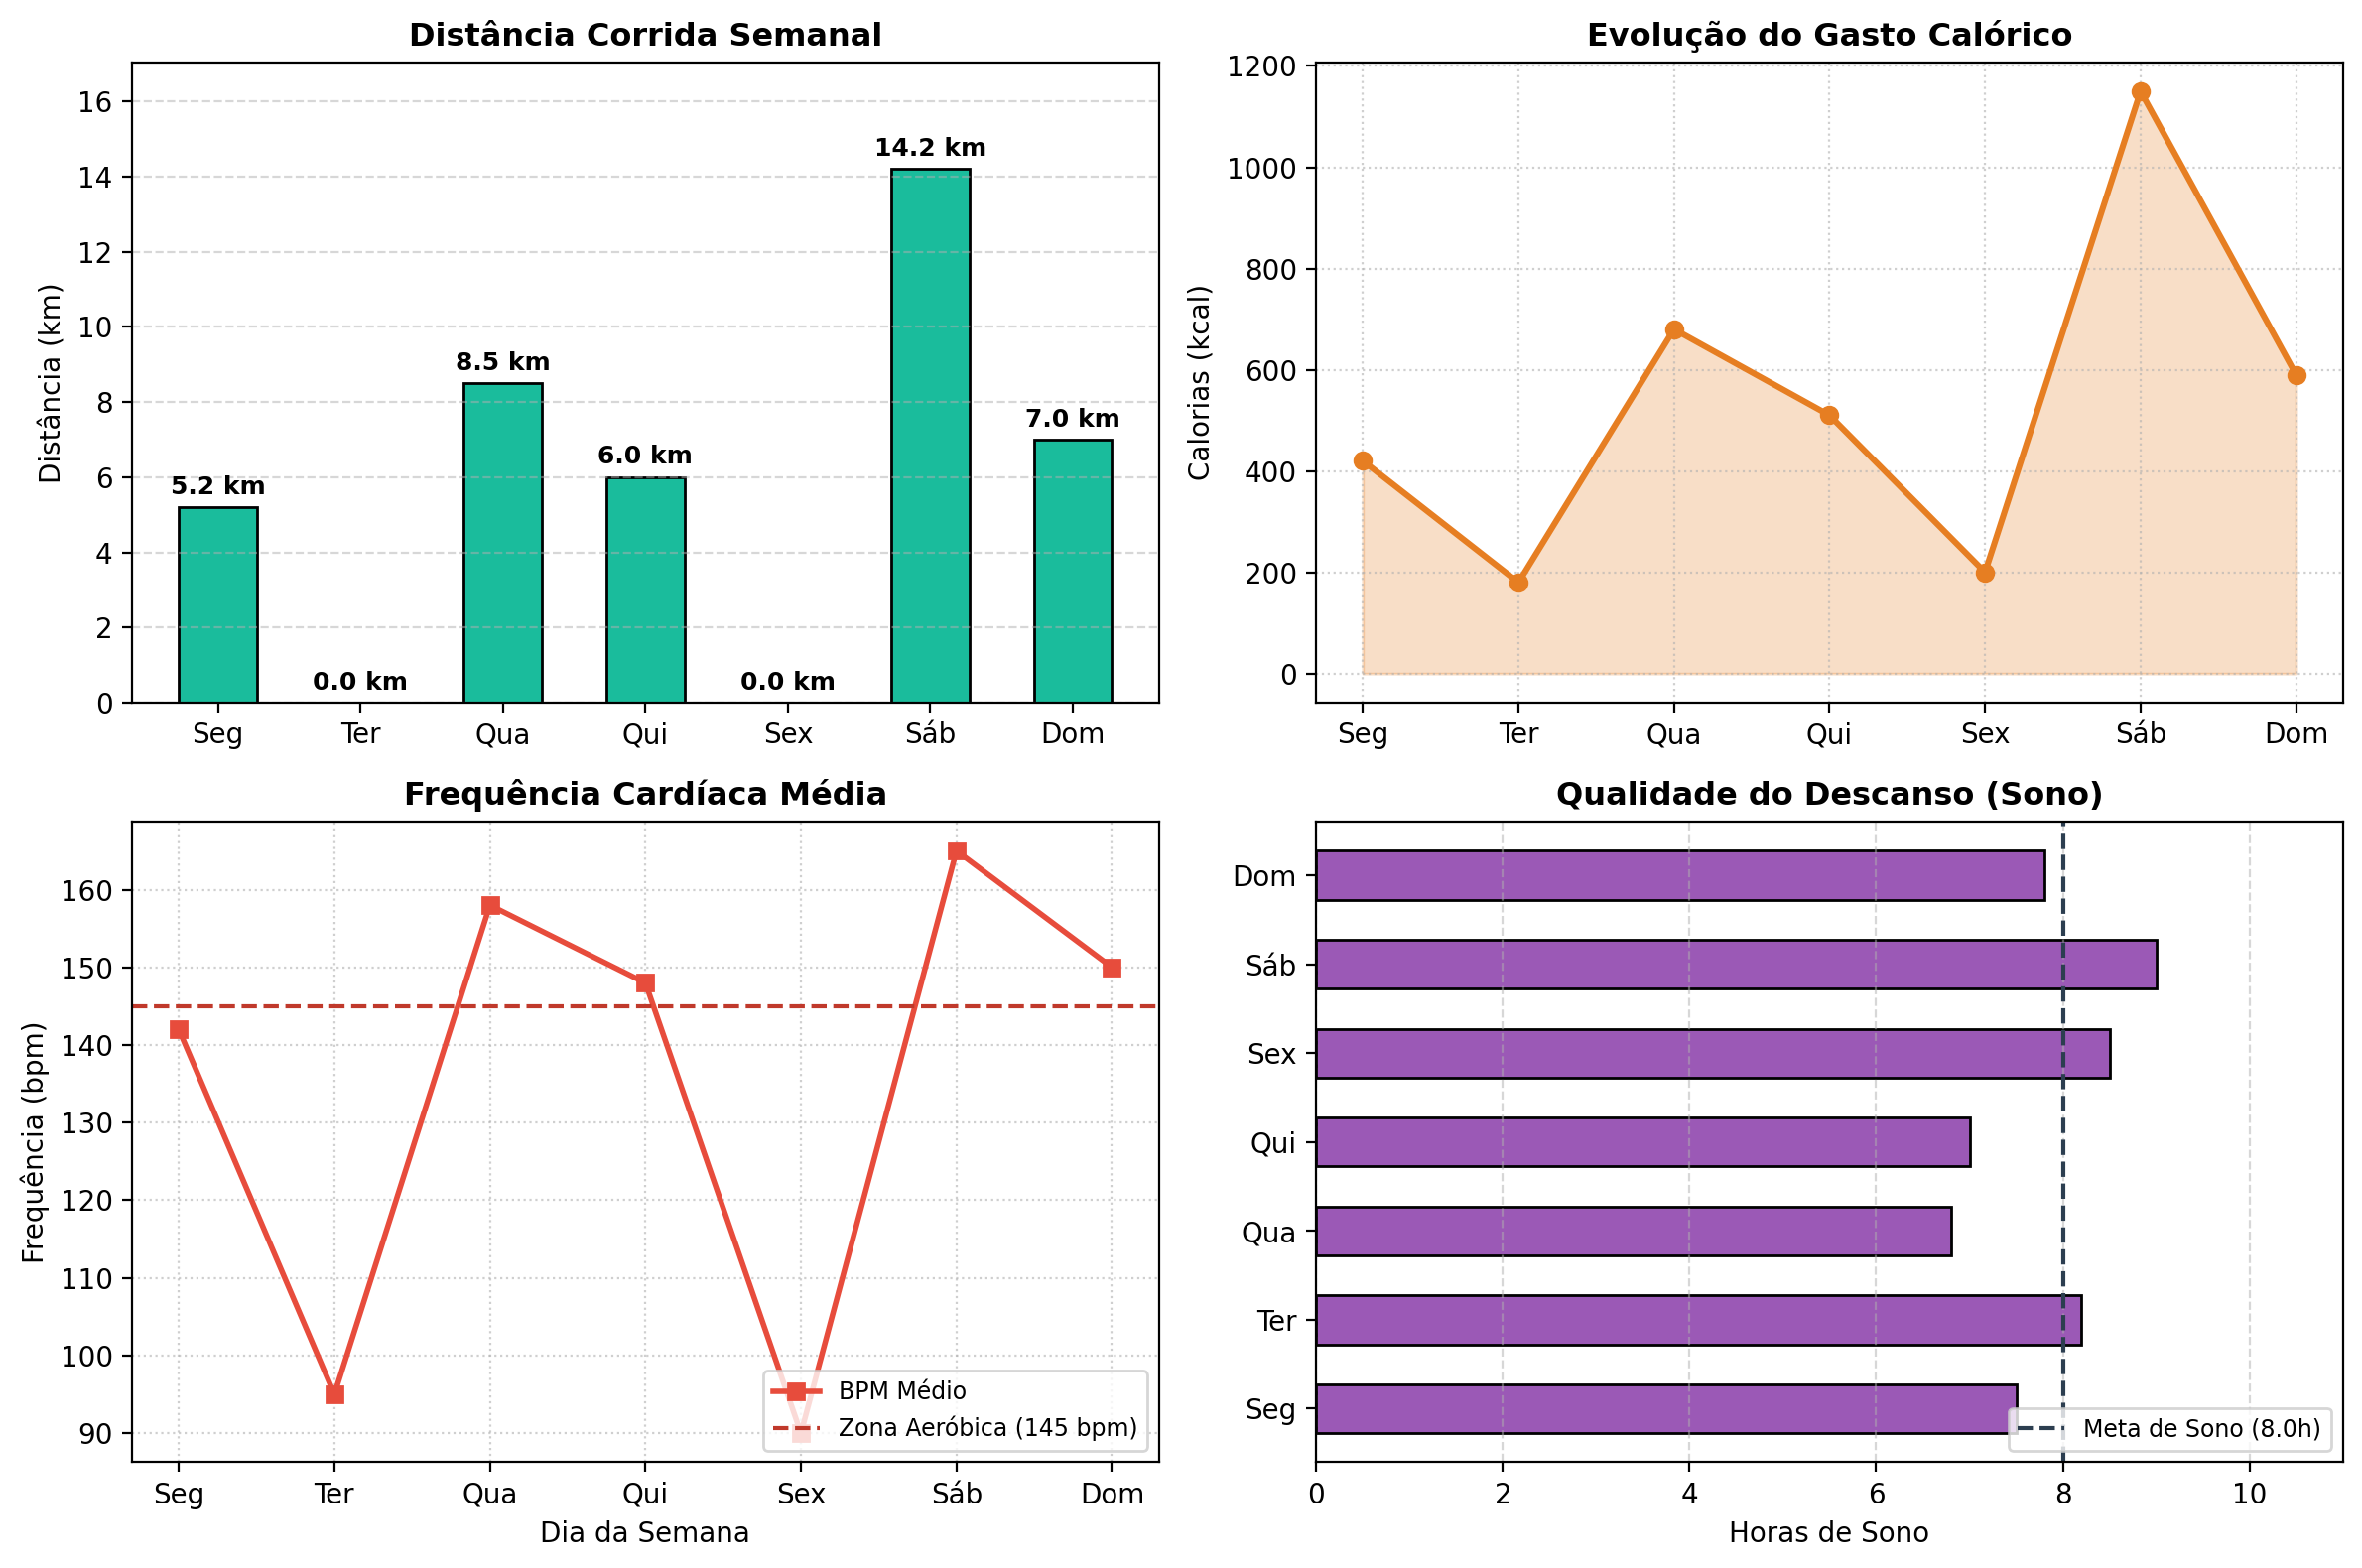

In [37]:
# Resposta Comentada: Exercício 6
import matplotlib.pyplot as plt
import numpy as np

def gerar_dashboard_fitness(dias: list[str], km: list[float], calorias: list[int], bpm: list[int], sono: list[float]) -> tuple[plt.Figure, np.ndarray]:
    # 1. Cria a grade 2x2 de subgráficos
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
    
    # --- Subgráfico (0, 0): Distância Corrida (Barras) ---
    barras_km = axes[0, 0].bar(dias, km, color='#1abc9c', edgecolor='black', width=0.55)
    axes[0, 0].bar_label(barras_km, fmt='%.1f km', padding=3, fontsize=9, fontweight='bold')
    axes[0, 0].set_title('Distância Corrida Semanal', fontsize=11.5, fontweight='bold')
    axes[0, 0].set_ylabel('Distância (km)')
    axes[0, 0].set_ylim(0, max(km) * 1.2)
    axes[0, 0].grid(axis='y', linestyle='--', alpha=0.5)
    
    # --- Subgráfico (0, 1): Calorias Queimadas (Linha + Fill) ---
    axes[0, 1].plot(dias, calorias, color='#e67e22', marker='o', linewidth=2.2, label='Calorias Gastas')
    axes[0, 1].fill_between(range(len(dias)), calorias, color='#e67e22', alpha=0.25)
    axes[0, 1].set_title('Evolução do Gasto Calórico', fontsize=11.5, fontweight='bold')
    axes[0, 1].set_ylabel('Calorias (kcal)')
    axes[0, 1].grid(True, linestyle=':', alpha=0.6)
    
    # --- Subgráfico (1, 0): Frequência Cardíaca (Linha + Meta) ---
    axes[1, 0].plot(dias, bpm, color='#e74c3c', marker='s', linewidth=2, label='BPM Médio')
    axes[1, 0].axhline(145, color='#c0392b', linestyle='--', linewidth=1.5, label='Zona Aeróbica (145 bpm)')
    axes[1, 0].set_title('Frequência Cardíaca Média', fontsize=11.5, fontweight='bold')
    axes[1, 0].set_xlabel('Dia da Semana')
    axes[1, 0].set_ylabel('Frequência (bpm)')
    axes[1, 0].grid(True, linestyle=':', alpha=0.6)
    axes[1, 0].legend(loc='lower right', fontsize=8.5)
    
    # --- Subgráfico (1, 1): Horas de Sono (Barras Horizontais) ---
    barras_sono = axes[1, 1].barh(dias, sono, color='#9b59b6', edgecolor='black', height=0.55)
    axes[1, 1].axvline(8.0, color='#2c3e50', linestyle='--', linewidth=1.5, label='Meta de Sono (8.0h)')
    axes[1, 1].set_title('Qualidade do Descanso (Sono)', fontsize=11.5, fontweight='bold')
    axes[1, 1].set_xlabel('Horas de Sono')
    axes[1, 1].set_xlim(0, 11)
    axes[1, 1].grid(axis='x', linestyle='--', alpha=0.5)
    axes[1, 1].legend(loc='lower right', fontsize=8.5)
    
    # 2. Ajuste automático dos espaçamentos entre subgráficos
    plt.tight_layout()
    
    return fig, axes

# Executando o teste da solução:
dias_semana = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
km_semana = [5.2, 0.0, 8.5, 6.0, 0.0, 14.2, 7.0]
cal_semana = [420, 180, 680, 510, 200, 1150, 590]
bpm_semana = [142, 95, 158, 148, 90, 165, 150]
sono_semana = [7.5, 8.2, 6.8, 7.0, 8.5, 9.0, 7.8]

fig, axes = gerar_dashboard_fitness(dias_semana, km_semana, cal_semana, bpm_semana, sono_semana)
plt.show()


---

## 8. Conclusão e Resumo da Aula

Parabéns por concluir a **Aula 15**! Você adquiriu uma das ferramentas mais poderosas para transformar dados brutos em histórias visuais claras e impactantes.

### 📌 Principais Aprendizados de Hoje:
* **Arquitetura `Figure` e `Axes`**: Entendeu como o Matplotlib estrutura a tela e a área gráfica, adotando a abordagem recomendada orientada a objetos (`fig, ax = plt.subplots()`).
* **Gráficos de Linha (`ax.plot`)**: Aprendeu a mapear séries temporais e funções matemáticas, personalizando cores, traços, marcadores, áreas preenchidas (`fill_between`) e linhas de referência (`axhline`, `axvline`).
* **Gráficos de Dispersão Multidimensionais (`ax.scatter`)**: Dominou a exibição de 4 dimensões de dados em 2D usando posições $X/Y$, tamanho dos pontos (`s`) e mapa de cores contínuo (`c`, `cmap`, `colorbar`).
* **Comparações Categóricas (`ax.bar`, `ax.barh`)**: Criou gráficos de barras com coloração condicional dinâmica e anotações automáticas nos topos das barras com `bar_label`.
* **Distribuição Estatística (`ax.hist`)**: Construiu histogramas com sobreposição, controle de transparência (`alpha`) e demarcação de medidas de tendência central (média e mediana).
* **Dashboards e Múltiplos Subgráficos (`plt.subplots(N, M)`)**: Aprendeu a construir painéis analíticos completos e utilizar `plt.tight_layout()` para uma apresentação visual limpa e profissional.

---
